# Electric Vehicle Adoption Trends in India

## State-wise and Fuel-type Analysis

This project analyses electric vehicle registration trends across Indian states using VAHAN vehicle registration data from January 2019 to May 2024.

### Business Question

How have electric vehicle registrations evolved across Indian states and fuel types, and which states show the strongest EV adoption trends?

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("../data/raw/ev_registrations_raw.csv")

df.head()

,id,date,state_name,state_code,office_name,office_code,fuel_type,category,registrations
0,0,2020-04-01,Andaman And Nicobar Islands,35,Port Blair Dto,AN1,Diesel,Fuel,36.0
1,1,2020-04-01,Andaman And Nicobar Islands,35,Port Blair Dto,AN1,Petrol,Fuel,122.0
2,2,2020-08-01,Andaman And Nicobar Islands,35,Port Blair Dto,AN1,Diesel,Fuel,1.0
3,3,2020-12-01,Andaman And Nicobar Islands,35,Port Blair Dto,AN1,Diesel,Fuel,24.0
4,4,2020-12-01,Andaman And Nicobar Islands,35,Port Blair Dto,AN1,Electric(Bov),Fuel,2.0


In [3]:
df.shape

(418372, 9)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418372 entries, 0 to 418371
Data columns (total 9 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   id             418372 non-null  int64  
 1   date           418372 non-null  object 
 2   state_name     418372 non-null  object 
 3   state_code     418372 non-null  int64  
 4   office_name    418372 non-null  object 
 5   office_code    418372 non-null  object 
 6   fuel_type      418372 non-null  object 
 7   category       418372 non-null  object 
 8   registrations  418372 non-null  float64
dtypes: float64(1), int64(2), object(6)
memory usage: 28.7+ MB


In [5]:
df["date"].min(), df["date"].max()

('2019-01-01', '2024-05-01')

In [6]:
df["fuel_type"].unique()

array(['Diesel', 'Petrol', 'Electric(Bov)', 'Not Applicable',
       'Petrol/Hybrid', 'Petrol/Ethanol', 'Strong Hybrid Ev',
       'Petrol/Cng', 'Cng Only', 'Pure Ev', 'Petrol/Lpg', 'Diesel/Hybrid',
       'Lpg Only', 'Ethanol', 'Lng', 'Methanol', 'Dual Diesel/Bio Cng',
       'Dual Diesel/Cng', 'Solar', 'Dual Diesel/Lng',
       'Fuel Cell Hydrogen', 'Plug-In Hybrid Ev'], dtype=object)

In [7]:
df["fuel_type"].value_counts()

fuel_type
Petrol                 82094
Diesel                 81597
Petrol/Hybrid          59219
Electric(Bov)          55305
Petrol/Cng             43149
Cng Only               23074
Not Applicable         22206
Petrol/Ethanol         15582
Petrol/Lpg             13373
Diesel/Hybrid          11001
Lpg Only                8452
Strong Hybrid Ev        1470
Pure Ev                 1462
Lng                      134
Ethanol                   82
Dual Diesel/Cng           73
Methanol                  55
Dual Diesel/Bio Cng       20
Solar                      8
Dual Diesel/Lng            8
Fuel Cell Hydrogen         6
Plug-In Hybrid Ev          2
Name: count, dtype: int64

In [8]:
df.isna().sum()

id               0
date             0
state_name       0
state_code       0
office_name      0
office_code      0
fuel_type        0
category         0
registrations    0
dtype: int64

In [9]:
df["registrations"].describe()

count    4.183720e+05
mean     1.844822e+03
std      5.581984e+04
min      1.000000e+00
25%      5.000000e+00
50%      2.600000e+01
75%      1.700000e+02
max      1.598869e+07
Name: registrations, dtype: float64

In [10]:
df.nlargest(20, "registrations")

,id,date,state_name,state_code,office_name,office_code,fuel_type,category,registrations
8197,8197,2020-01-01,Andhra Pradesh,28,Narasaraopet Rta,AP107,Petrol,Fuel,15988691.0
4998,4998,2021-01-01,Andhra Pradesh,28,Hindupur Rta,AP102,Petrol,Fuel,15896643.0
19060,19060,2023-11-01,Arunachal Pradesh,12,Lower Siang,AR22,Petrol,Fuel,2327086.0
255735,255735,2023-11-01,Rajasthan,8,Sikar Vehicle Fitness Center,RJ212,Petrol,Fuel,2327083.0
4900,4900,2020-03-01,Andhra Pradesh,28,Hindupur Rta,AP102,Petrol,Fuel,2214294.0
7315,7315,2020-03-01,Andhra Pradesh,28,Markapur Uo,AP327,Petrol,Fuel,2214294.0
8231,8231,2020-03-01,Andhra Pradesh,28,Narasaraopet Rta,AP107,Petrol,Fuel,2214294.0
18646,18646,2020-03-01,Arunachal Pradesh,12,Lower Siang,AR22,Petrol,Fuel,2214291.0
29438,29438,2020-03-01,Bihar,10,Bettiah,BR22,Petrol,Fuel,2214291.0
102501,102501,2020-03-01,Himachal Pradesh,2,Rla Shimla(Rural),HP51,Petrol,Fuel,2214287.0


## Initial Observations

- The dataset contains 418,372 rows and 9 columns.
- There are no missing values in any column.
- The `date` column is stored as text and needs to be converted to datetime format.
- The dataset spans from January 2019 through May 2024.
- The `category` column contains only one value, `Fuel`, and is not useful for analysis.
- The dataset includes multiple fuel types, including petrol, diesel, CNG, hybrid, and electric vehicles.
- Electric-vehicle records are identified by `Electric(Bov)` and `Pure Ev`.
- `Strong Hybrid Ev` and `Plug-In Hybrid Ev` are hybrid categories and should be analysed separately from pure electric vehicles.

In [11]:
df["date"] = pd.to_datetime(df["date"])

df["date"].min(), df["date"].max()

(Timestamp('2019-01-01 00:00:00'), Timestamp('2024-05-01 00:00:00'))

In [12]:
df["state_name"].unique()

array(['Andaman And Nicobar Islands', 'Andhra Pradesh',
       'Arunachal Pradesh', 'Assam', 'Bihar', 'Chandigarh',
       'Chhattisgarh', 'Delhi', 'Goa', 'Gujarat', 'Haryana',
       'Himachal Pradesh', 'Jammu And Kashmir', 'Jharkhand', 'Karnataka',
       'Kerala', 'Ladakh', 'Madhya Pradesh', 'Maharashtra', 'Manipur',
       'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Puducherry',
       'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Tripura',
       'The Dadra And Nagar Haveli And Daman And Diu', 'Uttar Pradesh',
       'Uttarakhand', 'West Bengal'], dtype=object)

In [13]:
df["state_name"].nunique()

34

In [14]:
df[["date", "state_name", "office_name", "fuel_type"]].duplicated().sum()

np.int64(61)

In [15]:
df["registrations"].sort_values(ascending=False).head(20)

8197      15988691.0
4998      15896643.0
19060      2327086.0
255735     2327083.0
4900       2214294.0
7315       2214294.0
8231       2214294.0
18646      2214291.0
29438      2214291.0
264105     2214287.0
167541     2214287.0
235773     2214287.0
299826     2214287.0
102501     2214287.0
261299     2214287.0
154993     2214287.0
286761     2214287.0
272190     2214287.0
227445     2214287.0
301084     2214287.0
Name: registrations, dtype: float64

In [16]:
df[df["registrations"] > 100000]

,id,date,state_name,state_code,office_name,office_code,fuel_type,category,registrations
4820,4820,2020-04-01,Andhra Pradesh,28,Hindupur Rta,AP102,Petrol,Fuel,429428.0
4825,4825,2020-08-01,Andhra Pradesh,28,Hindupur Rta,AP102,Diesel,Fuel,148818.0
4831,4831,2020-08-01,Andhra Pradesh,28,Hindupur Rta,AP102,Petrol,Fuel,1208404.0
4836,4836,2020-12-01,Andhra Pradesh,28,Hindupur Rta,AP102,Diesel,Fuel,201326.0
4841,4841,2020-12-01,Andhra Pradesh,28,Hindupur Rta,AP102,Petrol,Fuel,1851124.0
...,...,...,...,...,...,...,...,...,...
342948,342948,2020-11-01,West Bengal,19,Howrah Rto,WB11,Petrol,Fuel,1876913.0
342953,342953,2020-10-01,West Bengal,19,Howrah Rto,WB11,Diesel,Fuel,169797.0
342958,342958,2020-10-01,West Bengal,19,Howrah Rto,WB11,Petrol,Fuel,1433319.0
342963,342963,2020-09-01,West Bengal,19,Howrah Rto,WB11,Diesel,Fuel,173304.0


In [17]:
duplicate_rows = df[df.duplicated(
    subset=["date", "state_name", "office_name", "fuel_type"],
    keep=False
)]

duplicate_rows.head(20)

,id,date,state_name,state_code,office_name,office_code,fuel_type,category,registrations
252206,252206,2021-11-01,Rajasthan,8,Pipar City Dto,RJ54,Petrol,Fuel,168.0
252262,252262,2022-07-01,Rajasthan,8,Pipar City Dto,RJ54,Petrol,Fuel,241.0
252325,252325,2023-12-01,Rajasthan,8,Pipar City Dto,RJ54,Cng Only,Fuel,6.0
252326,252326,2023-12-01,Rajasthan,8,Pipar City Dto,RJ54,Diesel,Fuel,66.0
252327,252327,2023-12-01,Rajasthan,8,Pipar City Dto,RJ54,Electric(Bov),Fuel,20.0
252329,252329,2023-12-01,Rajasthan,8,Pipar City Dto,RJ54,Petrol,Fuel,260.0
252330,252330,2023-12-01,Rajasthan,8,Pipar City Dto,RJ54,Petrol/Cng,Fuel,11.0
252354,252354,2023-06-01,Rajasthan,8,Pipar City Dto,RJ54,Cng Only,Fuel,8.0
252355,252355,2023-06-01,Rajasthan,8,Pipar City Dto,RJ54,Diesel,Fuel,305.0
252356,252356,2023-06-01,Rajasthan,8,Pipar City Dto,RJ54,Electric(Bov),Fuel,10.0


In [18]:
df.nlargest(20, "registrations")[
    ["date", "state_name", "office_name", "fuel_type", "registrations"]
]

,date,state_name,office_name,fuel_type,registrations
8197,2020-01-01,Andhra Pradesh,Narasaraopet Rta,Petrol,15988691.0
4998,2021-01-01,Andhra Pradesh,Hindupur Rta,Petrol,15896643.0
19060,2023-11-01,Arunachal Pradesh,Lower Siang,Petrol,2327086.0
255735,2023-11-01,Rajasthan,Sikar Vehicle Fitness Center,Petrol,2327083.0
4900,2020-03-01,Andhra Pradesh,Hindupur Rta,Petrol,2214294.0
7315,2020-03-01,Andhra Pradesh,Markapur Uo,Petrol,2214294.0
8231,2020-03-01,Andhra Pradesh,Narasaraopet Rta,Petrol,2214294.0
18646,2020-03-01,Arunachal Pradesh,Lower Siang,Petrol,2214291.0
29438,2020-03-01,Bihar,Bettiah,Petrol,2214291.0
102501,2020-03-01,Himachal Pradesh,Rla Shimla(Rural),Petrol,2214287.0


## Data Quality Findings

- The dataset contains 61 duplicate records based on business key (date, state, RTO office, fuel type), though 0 full-row duplicates across all 9 columns.
- Some duplicate records have slightly different registration values, suggesting revised or repeated source records.
- The highest registration values are petrol records, with values above 15 million.
- Multiple RTO offices report the same petrol registration value in March 2020, indicating likely aggregation or reporting errors.
- These extreme petrol values are not relevant to the main EV adoption analysis but must be handled before comparing fuel types.

In [19]:
ev_types = ["Electric(Bov)", "Pure Ev"]

df[df["fuel_type"].isin(ev_types)]["registrations"].describe()

count     56767.000000
mean        309.555235
std        4570.231064
min           1.000000
25%           4.000000
50%          18.000000
75%          66.000000
max      331584.000000
Name: registrations, dtype: float64

In [20]:
df[df["fuel_type"].isin(ev_types)].nlargest(20, "registrations")[
    ["date", "state_name", "office_name", "fuel_type", "registrations"]
]

,date,state_name,office_name,fuel_type,registrations
4993,2021-01-01,Andhra Pradesh,Hindupur Rta,Electric(Bov),331584.0
255806,2024-03-01,Rajasthan,Sikar Vehicle Fitness Center,Electric(Bov),209707.0
255719,2023-05-01,Rajasthan,Sikar Vehicle Fitness Center,Electric(Bov),158464.0
19044,2023-05-01,Arunachal Pradesh,Lower Siang,Electric(Bov),158462.0
19056,2023-11-01,Arunachal Pradesh,Lower Siang,Electric(Bov),154128.0
255731,2023-11-01,Rajasthan,Sikar Vehicle Fitness Center,Electric(Bov),154128.0
255795,2024-01-01,Rajasthan,Sikar Vehicle Fitness Center,Electric(Bov),145011.0
255649,2023-12-01,Rajasthan,Sikar Vehicle Fitness Center,Electric(Bov),141929.0
18974,2023-12-01,Arunachal Pradesh,Lower Siang,Electric(Bov),141926.0
255782,2024-02-01,Rajasthan,Sikar Vehicle Fitness Center,Electric(Bov),141699.0


## EV Data Quality Check

- Checking EV records reveals extreme registration values, including more than 300,000 registrations for a single RTO office in one month.
- Similar high values appear across different RTO offices, suggesting possible aggregation or reporting errors.
- These values must be investigated before calculating state-wise EV rankings or monthly EV trends.

In [21]:
suspect_offices = [
    "Hindupur Rta",
    "Sikar Vehicle Fitness Center",
    "Lower Siang"
]


df[
    (df["fuel_type"].isin(ev_types))
    & (df["office_name"].isin(suspect_offices))
][["date", "state_name", "office_name", "fuel_type", "registrations"]].sort_values(
    ["office_name", "date"]
)

,date,state_name,office_name,fuel_type,registrations
351281,2019-01-01,Andhra Pradesh,Hindupur Rta,Electric(Bov),3.0
351277,2019-02-01,Andhra Pradesh,Hindupur Rta,Electric(Bov),7.0
351292,2019-03-01,Andhra Pradesh,Hindupur Rta,Electric(Bov),9.0
351297,2019-05-01,Andhra Pradesh,Hindupur Rta,Electric(Bov),4.0
351288,2019-06-01,Andhra Pradesh,Hindupur Rta,Electric(Bov),34.0
...,...,...,...,...,...
255816,2024-03-01,Rajasthan,Sikar Vehicle Fitness Center,Pure Ev,3221.0
255767,2024-04-01,Rajasthan,Sikar Vehicle Fitness Center,Electric(Bov),113223.0
255777,2024-04-01,Rajasthan,Sikar Vehicle Fitness Center,Pure Ev,2507.0
255822,2024-05-01,Rajasthan,Sikar Vehicle Fitness Center,Electric(Bov),123623.0


In [22]:
ev_df = df[df["fuel_type"].isin(ev_types)].copy()

ev_df[ev_df["registrations"] > 10000].shape

(281, 9)

In [23]:
ev_df[ev_df["registrations"] > 10000][
    ["date", "state_name", "office_name", "registrations"]
].sort_values("registrations", ascending=False).head(30)

,date,state_name,office_name,registrations
4993,2021-01-01,Andhra Pradesh,Hindupur Rta,331584.0
255806,2024-03-01,Rajasthan,Sikar Vehicle Fitness Center,209707.0
255719,2023-05-01,Rajasthan,Sikar Vehicle Fitness Center,158464.0
19044,2023-05-01,Arunachal Pradesh,Lower Siang,158462.0
255731,2023-11-01,Rajasthan,Sikar Vehicle Fitness Center,154128.0
19056,2023-11-01,Arunachal Pradesh,Lower Siang,154128.0
255795,2024-01-01,Rajasthan,Sikar Vehicle Fitness Center,145011.0
255649,2023-12-01,Rajasthan,Sikar Vehicle Fitness Center,141929.0
18974,2023-12-01,Arunachal Pradesh,Lower Siang,141926.0
255782,2024-02-01,Rajasthan,Sikar Vehicle Fitness Center,141699.0


In [24]:
ev_df["registrations"].describe()

count     56767.000000
mean        309.555235
std        4570.231064
min           1.000000
25%           4.000000
50%          18.000000
75%          66.000000
max      331584.000000
Name: registrations, dtype: float64

In [25]:
monthly_ev = (
    ev_df
    .groupby(ev_df["date"].dt.to_period("M"))["registrations"]
    .sum()
    .reset_index()
)

monthly_ev["date"] = monthly_ev["date"].dt.to_timestamp()

monthly_ev

,date,registrations
0,2019-01-01,13758.0
1,2019-02-01,12398.0
2,2019-03-01,15286.0
3,2019-04-01,11391.0
4,2019-05-01,10230.0
...,...,...
60,2024-01-01,298786.0
61,2024-02-01,291960.0
62,2024-03-01,438700.0
63,2024-04-01,238455.0


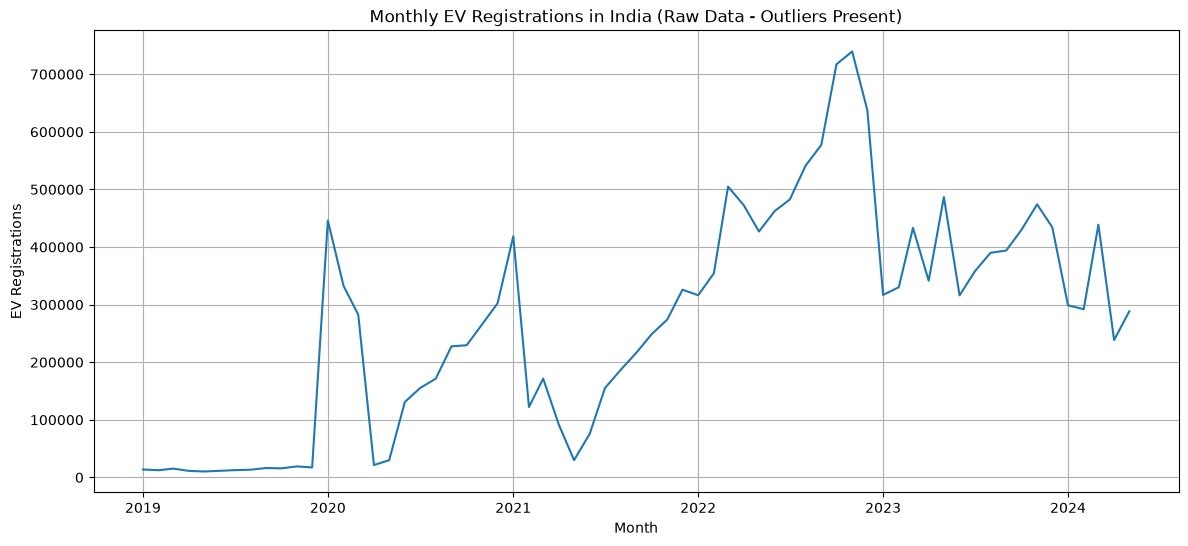

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
plt.plot(monthly_ev["date"], monthly_ev["registrations"])
plt.title("Monthly EV Registrations in India (Raw Data - Outliers Present)")
plt.xlabel("Month")
plt.ylabel("EV Registrations")
plt.grid(True)
plt.show()

## Monthly EV Registration Trend

The monthly EV registration trend shows an overall increase in EV adoption from 2019 to 2024. 
EV registrations were relatively low in the early years and increased substantially from 2022 onwards.

Monthly values fluctuate, which is normal for vehicle registration data. March 2024 recorded the highest monthly EV registrations.

In [27]:
ev_df["year_month"] = ev_df["date"].dt.to_period("M")

top_months = (
    ev_df.groupby("year_month")["registrations"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

top_months

year_month
2022-11    739494.0
2022-10    717274.0
2022-12    637172.0
2022-09    577170.0
2022-08    541225.0
Freq: M, Name: registrations, dtype: float64

## Data Cleaning Decision

1. **Outlier Filtering**: The dataset contains unusually high EV registration values at the RTO-office level (e.g. >300,000 in a month). Records with more than 10,000 registrations per RTO office per month were treated as reporting anomalies and excluded.

2. **Redundant Column Removal**: The `category` column (constant value `'Fuel'`) and temporary `year_month` column are dropped to keep the exported schema normalized and lean for SQL ingestion.

3. **Data Type Correction**: The `registrations` column is converted from `float` to `int` since vehicle counts represent discrete physical units.

The original raw dataset remains unchanged.

In [28]:
ev_df_clean = (
    ev_df[ev_df["registrations"] <= 10000]
    .drop(columns=["category", "year_month"], errors="ignore")
    .copy()
)
ev_df_clean["registrations"] = ev_df_clean["registrations"].astype(int)

print(f"Cleaned EV records: {len(ev_df_clean):,}")
print("Remaining columns:", ev_df_clean.columns.tolist())
ev_df_clean.head(3)

Cleaned EV records: 56,486
Remaining columns: ['id', 'date', 'state_name', 'state_code', 'office_name', 'office_code', 'fuel_type', 'registrations']


,id,date,state_name,state_code,office_name,office_code,fuel_type,registrations
4,4,2020-12-01,Andaman And Nicobar Islands,35,Port Blair Dto,AN1,Electric(Bov),2
7,7,2020-02-01,Andaman And Nicobar Islands,35,Port Blair Dto,AN1,Electric(Bov),3
12,12,2020-07-01,Andaman And Nicobar Islands,35,Port Blair Dto,AN1,Electric(Bov),15


## Business Question 1

### How has EV adoption changed in India over time?

To understand EV adoption over time, we analyse monthly EV registrations from 2019 to 2024. 
This helps identify whether EV adoption is increasing and whether there are any major changes 
in registration trends.

In [29]:
monthly_ev = (
    ev_df_clean
    .groupby(ev_df_clean["date"].dt.to_period("M"))["registrations"]
    .sum()
    .reset_index()
)

monthly_ev["date"] = monthly_ev["date"].dt.to_timestamp()

monthly_ev

,date,registrations
0,2019-01-01,13758
1,2019-02-01,12398
2,2019-03-01,15286
3,2019-04-01,11391
4,2019-05-01,10230
...,...,...
60,2024-01-01,153775
61,2024-02-01,150261
62,2024-03-01,217765
63,2024-04-01,125232


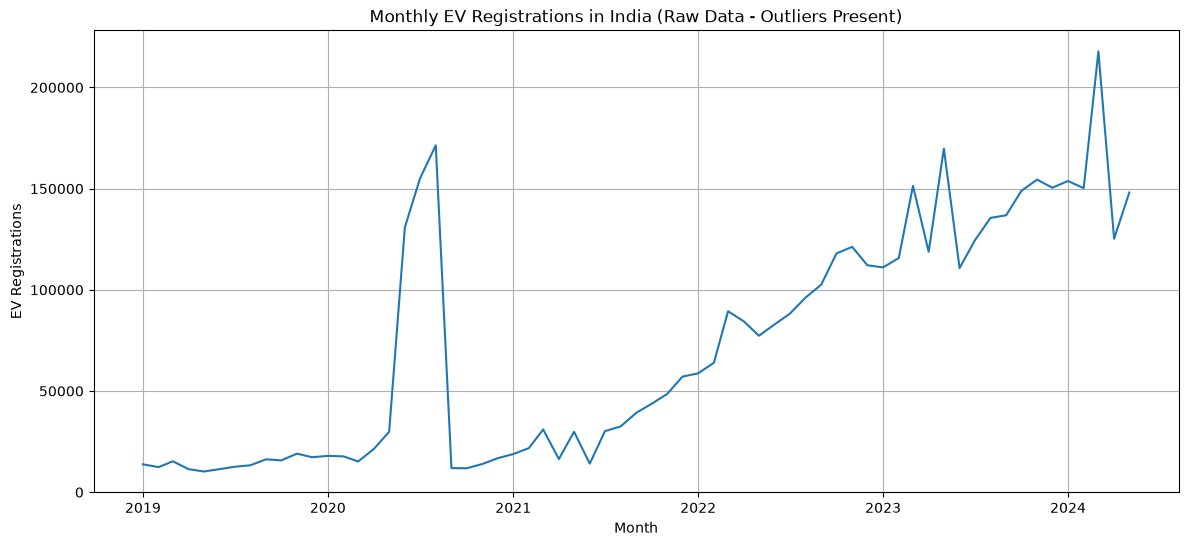

In [30]:
plt.figure(figsize=(14, 6))
plt.plot(monthly_ev["date"], monthly_ev["registrations"])
plt.title("Monthly EV Registrations in India (Raw Data - Outliers Present)")
plt.xlabel("Month")
plt.ylabel("EV Registrations")
plt.grid(True)
plt.show()

## Business Question 2

### Which states have the highest EV registrations?

To identify the leading EV markets in India, we analyse total EV registrations by state. 
This helps identify states with the highest EV adoption.

In [31]:
top_states = (
    ev_df_clean.groupby("state_name")["registrations"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_states

state_name
Uttar Pradesh     728875
Maharashtra       471927
Rajasthan         457199
Tamil Nadu        418258
Karnataka         372689
Bihar             259020
Delhi             256944
Gujarat           201918
Kerala            190599
Madhya Pradesh    186532
Name: registrations, dtype: int64

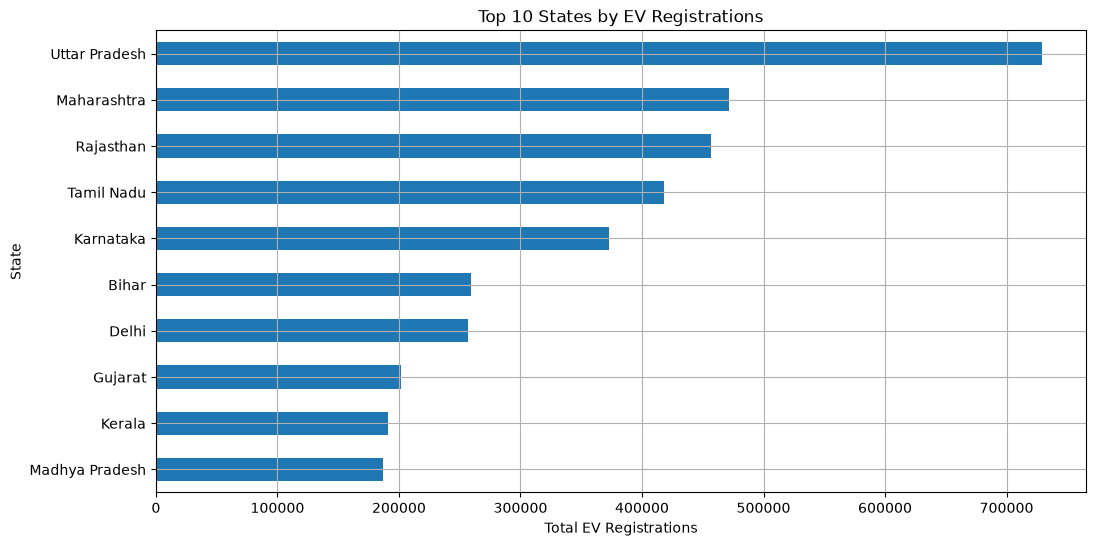

In [32]:
plt.figure(figsize=(12, 6))
top_states.sort_values().plot(kind="barh")
plt.title("Top 10 States by EV Registrations")
plt.xlabel("Total EV Registrations")
plt.ylabel("State")
plt.grid(True)
plt.show()

## Business Question 3

### How do EV registrations compare with petrol and diesel vehicles?

To understand the position of EVs in the overall vehicle market, we compare total 
registrations across major fuel types. To ensure an accurate and realistic comparison, 
we apply the same outlier threshold (<= 10,000 registrations per RTO office/month) 
to exclude corrupted petrol reporting spikes.

In [33]:
# Filter extreme reporting outliers to ensure accurate cross-fuel comparison
fuel_df_clean = df[df["registrations"] <= 10000]

fuel_type_total = (
    fuel_df_clean.groupby("fuel_type")["registrations"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

fuel_type_total

fuel_type
Petrol            91957833.0
Diesel            13037450.0
Electric(Bov)      4653046.0
Petrol/Cng         2543711.0
Not Applicable     2529667.0
Petrol/Hybrid      2192255.0
Cng Only           2121711.0
Petrol/Lpg         1104543.0
Petrol/Ethanol      675837.0
Lpg Only            489314.0
Name: registrations, dtype: float64

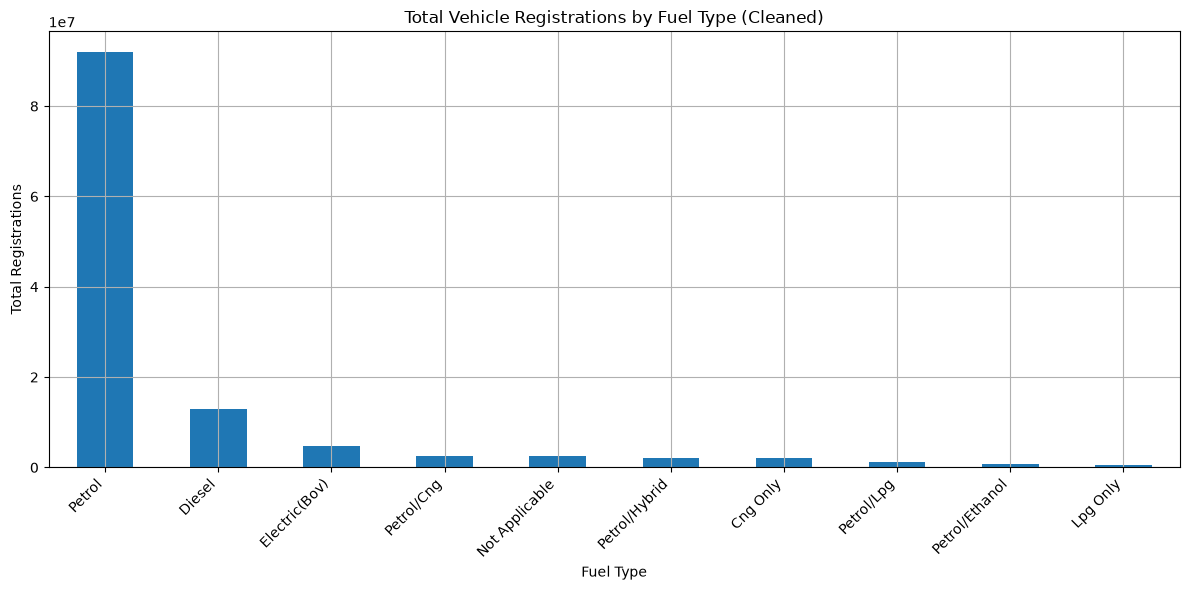

In [34]:
plt.figure(figsize=(12, 6))
fuel_type_total.plot(kind="bar")
plt.title("Total Vehicle Registrations by Fuel Type (Cleaned)")
plt.xlabel("Fuel Type")
plt.ylabel("Total Registrations")
plt.xticks(rotation=45, ha="right")
plt.grid(True)
plt.tight_layout()
plt.show()

## Fuel Type Comparison

Petrol and diesel vehicles still account for a large share of total registrations. 
However, EV registrations have increased over time and represent a growing segment 
of the Indian vehicle market.

## Business Question 4

### Which states lead EV registrations in recent years (2024)?

To identify leading and emerging EV markets, we examine EV registrations across states in 2024 (Jan - May) alongside 2023 figures.

In [35]:
recent_years = ev_df_clean[ev_df_clean["date"].dt.year.isin([2023, 2024])]

state_year_growth = (
    recent_years
    .groupby(["state_name", recent_years["date"].dt.year])["registrations"]
    .sum()
    .unstack()
)

state_year_growth.head(10)

date,2023,2024
state_name,,
Andaman And Nicobar Islands,26.0,29.0
Andhra Pradesh,32867.0,23611.0
Arunachal Pradesh,21.0,15.0
Assam,59885.0,25879.0
Bihar,88218.0,41680.0
Chandigarh,6407.0,2476.0
Chhattisgarh,38231.0,18245.0
Delhi,73657.0,35164.0
Goa,9483.0,5836.0


In [36]:
top_growth_states = (
    state_year_growth[2024]
    .sort_values(ascending=False)
    .head(10)
)

top_growth_states

state_name
Uttar Pradesh     133924.0
Maharashtra        96531.0
Rajasthan          78203.0
Karnataka          74942.0
Tamil Nadu         49112.0
Bihar              41680.0
Kerala             36196.0
Delhi              35164.0
Madhya Pradesh     34276.0
Gujarat            32472.0
Name: 2024, dtype: float64

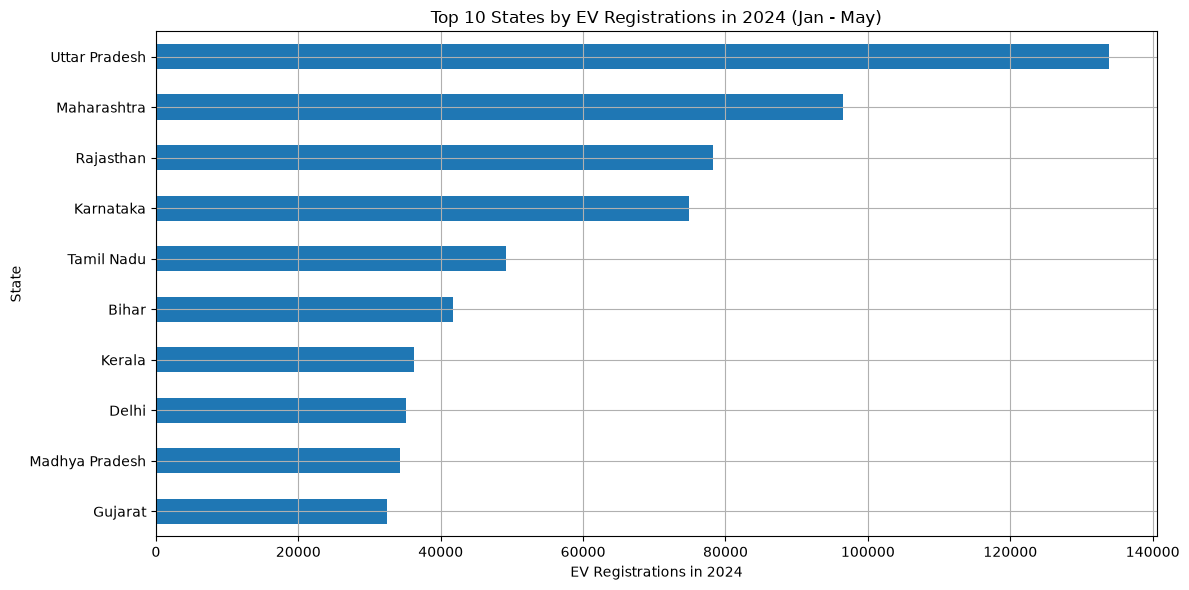

In [37]:
plt.figure(figsize=(12, 6))
top_growth_states.sort_values().plot(kind="barh")
plt.title("Top 10 States by EV Registrations in 2024 (Jan - May)")
plt.xlabel("EV Registrations in 2024")
plt.ylabel("State")
plt.grid(True)
plt.tight_layout()
plt.show()

## Recent EV Growth by State

The 2024 state-wise EV registrations highlight the states with the strongest recent EV market. 
These states may represent important markets for EV manufacturers, charging infrastructure, 
and policy support.

## Key Findings

- EV registrations in India increased substantially from 2019 to 2024.
- Monthly EV registrations fluctuate, but the overall trend shows strong long-term adoption.
- A few leading states (such as Uttar Pradesh, Maharashtra, Karnataka, and Rajasthan) account for a large share of total EV registrations.
- Petrol and diesel vehicles still dominate total cumulative volume, but EVs represent a fast-growing segment.
- Recent 2024 figures demonstrate continued expansion across major state corridors.

These findings can help EV manufacturers, policymakers, and charging-infrastructure 
companies identify high-potential markets and understand the growth of India's EV market.

## Limitations

- The dataset contains registration records, not the total number of vehicles currently on the road.
- Some RTO-level records showed unusually high values, so extreme EV records above 10,000 registrations per month were excluded.
- The analysis is based on one dataset and does not include charging infrastructure, income, population, or policy data.
- EV adoption may vary within states, so state-level results should not be interpreted as uniform across all districts.

## Export Cleaned Data for SQL

The cleaned EV registration dataset is exported as a CSV file. This file will be used for 
SQL-based analysis in the next stage of the project.

In [38]:
ev_df_clean.to_csv('../data/cleaned/ev_registrations_clean.csv', index=False)